
> ! sebelum running, upload dataset di folder sample_data terlebih dahulu !





# **1. IMPORT LIBRARY**
> Pada tahap ini, dilakukan pemanggilan seluruh pustaka (*library*) Python eksternal seperti Pandas, NumPy, Matplotlib, Seaborn, dan Scikit-Learn yang diperlukan untuk manipulasi data, visualisasi, serta pemodelan.



In [1]:
# Data Exploration, Analysis & Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

from scipy import stats
from scipy.stats import norm, chi2_contingency
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

import pprint

# Configure Environment
warnings.filterwarnings("ignore")
%matplotlib inline
sns.set(rc={"figure.figsize": (20, 15)})
sns.set_style("whitegrid")

# **2. LOAD DATASET**
> Tahap ini memuat data mentah dari berkas dataset.csv ke dalam struktur data berorientasi baris-kolom (Pandas DataFrame) serta menampilkan dimensi awal data tersebut.



In [2]:
# Load dataset
df_dataset = pd.read_csv("/content/sample_data/dataset.csv")
print(f"dataset shape:\n{df_dataset.shape}\n")

dataset shape:
(197428, 14)



insight : dataset berukuran 197.428 baris dengan 14 kolom (fitur)

# **3. EKSPLORASI DATA**

> memeriksa tipe data, jumlah nilai non-null, dan ringkasan informasi struktur kolom pada dataset. Tujuannya adalah untuk mendeteksi ketidaksesuaian tipe data dan memetakan fitur-fitur mana saja yang membutuhkan penanganan lebih lanjut sebelum masuk ke pemrosesan.




In [3]:
df_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197428 entries, 0 to 197427
Data columns (total 14 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   market_id                 196441 non-null  float64
 1   created_at                197428 non-null  object 
 2   actual_delivery_time      197421 non-null  object 
 3   store_id                  197428 non-null  object 
 4   store_primary_category    192668 non-null  object 
 5   order_protocol            196433 non-null  float64
 6   total_items               197428 non-null  int64  
 7   subtotal                  197428 non-null  int64  
 8   num_distinct_items        197428 non-null  int64  
 9   min_item_price            197428 non-null  int64  
 10  max_item_price            197428 non-null  int64  
 11  total_onshift_partners    181166 non-null  float64
 12  total_busy_partners       181166 non-null  float64
 13  total_outstanding_orders  181166 non-null  f

## 3.1. Pisahkan ID

> kolom identifikasi unik seperti market_id dan store_id dipisahkan terlebih dahulu dari dataset utama. Pemisahan ini berfungsi untuk mencegah model mempelajari data identitas acak yang tidak memiliki nilai prediksi, sekaligus menjaga kebersihan data latih agar tidak bias.




In [4]:
# Store the Id columns before dropping them
Id_dataset = df_dataset[['market_id', 'store_id']]

# Drop 'Id' columns from main dataset
df_dataset = df_dataset.drop(columns=['market_id', 'store_id'])

In [5]:
Id_dataset

,market_id,store_id
0,1.0,df263d996281d984952c07998dc54358
1,2.0,f0ade77b43923b38237db569b016ba25
2,3.0,f0ade77b43923b38237db569b016ba25
3,3.0,f0ade77b43923b38237db569b016ba25
4,3.0,f0ade77b43923b38237db569b016ba25
...,...,...
197423,1.0,a914ecef9c12ffdb9bede64bb703d877
197424,1.0,a914ecef9c12ffdb9bede64bb703d877
197425,1.0,a914ecef9c12ffdb9bede64bb703d877
197426,1.0,c81e155d85dae5430a8cee6f2242e82c


In [6]:
df_dataset

,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
0,2015-02-06 22:24:17,2015-02-06 23:27:16,american,1.0,4,3441,4,557,1239,33.0,14.0,21.0
1,2015-02-10 21:49:25,2015-02-10 22:56:29,mexican,2.0,1,1900,1,1400,1400,1.0,2.0,2.0
2,2015-01-22 20:39:28,2015-01-22 21:09:09,NaN,1.0,1,1900,1,1900,1900,1.0,0.0,0.0
3,2015-02-03 21:21:45,2015-02-03 22:13:00,NaN,1.0,6,6900,5,600,1800,1.0,1.0,2.0
4,2015-02-15 02:40:36,2015-02-15 03:20:26,NaN,1.0,3,3900,3,1100,1600,6.0,6.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...
197423,2015-02-17 00:19:41,2015-02-17 01:24:48,fast,4.0,3,1389,3,345,649,17.0,17.0,23.0
197424,2015-02-13 00:01:59,2015-02-13 00:58:22,fast,4.0,6,3010,4,405,825,12.0,11.0,14.0
197425,2015-01-24 04:46:08,2015-01-24 05:36:16,fast,4.0,5,1836,3,300,399,39.0,41.0,40.0
197426,2015-02-01 18:18:15,2015-02-01 19:23:22,sandwich,1.0,1,1175,1,535,535,7.0,7.0,12.0


## 3.2. Menangani missing value

> Menangani missing value Di sini dilakukan deteksi persentase data yang hilang serta pengisian (imputasi) nilai kosong, di mana kolom numerik diisi dengan nilai median sedangkan kolom kategorikal diisi dengan modus



In [7]:
missing_values = df_dataset.isna().sum()
missing_percentage = (missing_values / len(df_dataset)) * 100

missing_info = pd.DataFrame({
    'Jumlah Missing': missing_values,
    'Persentase (%)': missing_percentage
})
display(missing_info)

,Jumlah Missing,Persentase (%)
created_at,0,0.000000
actual_delivery_time,7,0.003546
store_primary_category,4760,2.411006
order_protocol,995,0.503981
total_items,0,0.000000
subtotal,0,0.000000
num_distinct_items,0,0.000000
min_item_price,0,0.000000
max_item_price,0,0.000000
total_onshift_partners,16262,8.236927


insight : didapati tidak ada kolom dengan missing values lebih dari 50%

**Imputasi Missing Values**

Kita akan melakukan imputasi nilai yang hilang:
- **Median** untuk kolom numerik (seperti `total_onshift_partners`, `total_busy_partners`, `total_outstanding_orders`).
- **Modus (Nilai Terbanyak)** untuk kolom kategorikal (seperti `store_primary_category`, `order_protocol`).
- Untuk target `actual_delivery_time`, karena bertipe datetime dan sangat krusial untuk target durasi pengiriman, baris dengan nilai kosong pada target ini sebaiknya dihapus (*drop*) ketimbang diimputasi agar tidak membiaskan model.

In [8]:
# 1. Hapus baris di mana actual_delivery_time bernilai null (karena ini penting untuk menghitung target duration_seconds)
df_dataset = df_dataset.dropna(subset=['actual_delivery_time'])

# 2. Definisikan kolom berdasarkan tipe datanya
num_cols = df_dataset.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_dataset.select_dtypes(include=['object']).columns.tolist()

# Jangan masukkan 'created_at' dan 'actual_delivery_time' ke dalam imputasi kategorikal standar
if 'created_at' in cat_cols: cat_cols.remove('created_at')
if 'actual_delivery_time' in cat_cols: cat_cols.remove('actual_delivery_time')

# 3. Imputasi Median untuk kolom numerik
for col in num_cols:
    median_val = df_dataset[col].median()
    df_dataset[col].fillna(median_val, inplace=True)
    print(f"Imputasi kolom numerik '{col}' dengan median: {median_val}")

# 4. Imputasi Modus untuk kolom kategorikal
for col in cat_cols:
    mode_val = df_dataset[col].mode()[0]
    df_dataset[col].fillna(mode_val, inplace=True)
    print(f"Imputasi kolom kategorikal '{col}' dengan modus: {mode_val}")

# 5. Cek kembali jumlah missing values
print("\nJumlah missing value setelah imputasi:")
print(df_dataset.isna().sum())

Imputasi kolom numerik 'order_protocol' dengan median: 3.0
Imputasi kolom numerik 'total_items' dengan median: 3.0
Imputasi kolom numerik 'subtotal' dengan median: 2200.0
Imputasi kolom numerik 'num_distinct_items' dengan median: 2.0
Imputasi kolom numerik 'min_item_price' dengan median: 595.0
Imputasi kolom numerik 'max_item_price' dengan median: 1095.0
Imputasi kolom numerik 'total_onshift_partners' dengan median: 37.0
Imputasi kolom numerik 'total_busy_partners' dengan median: 34.0
Imputasi kolom numerik 'total_outstanding_orders' dengan median: 41.0
Imputasi kolom kategorikal 'store_primary_category' dengan modus: american

Jumlah missing value setelah imputasi:
created_at                  0
actual_delivery_time        0
store_primary_category      0
order_protocol              0
total_items                 0
subtotal                    0
num_distinct_items          0
min_item_price              0
max_item_price              0
total_onshift_partners      0
total_busy_partners      

In [9]:
df_dataset

,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
0,2015-02-06 22:24:17,2015-02-06 23:27:16,american,1.0,4,3441,4,557,1239,33.0,14.0,21.0
1,2015-02-10 21:49:25,2015-02-10 22:56:29,mexican,2.0,1,1900,1,1400,1400,1.0,2.0,2.0
2,2015-01-22 20:39:28,2015-01-22 21:09:09,american,1.0,1,1900,1,1900,1900,1.0,0.0,0.0
3,2015-02-03 21:21:45,2015-02-03 22:13:00,american,1.0,6,6900,5,600,1800,1.0,1.0,2.0
4,2015-02-15 02:40:36,2015-02-15 03:20:26,american,1.0,3,3900,3,1100,1600,6.0,6.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...
197423,2015-02-17 00:19:41,2015-02-17 01:24:48,fast,4.0,3,1389,3,345,649,17.0,17.0,23.0
197424,2015-02-13 00:01:59,2015-02-13 00:58:22,fast,4.0,6,3010,4,405,825,12.0,11.0,14.0
197425,2015-01-24 04:46:08,2015-01-24 05:36:16,fast,4.0,5,1836,3,300,399,39.0,41.0,40.0
197426,2015-02-01 18:18:15,2015-02-01 19:23:22,sandwich,1.0,1,1175,1,535,535,7.0,7.0,12.0


## 3.3. Membuang Quasi Constan

> mencari variabel yang nilainya hampir seragam (konstan) dan mengeliminasi fitur minim informasi yang tidak berkontribusi pada kemampuan prediksi model guna merampingkan dimensi komputasi.




In [10]:
# 1. Ambil kolom bertipe numerik terlebih dahulu
df_dataset_num = df_dataset.select_dtypes(include=['int64', 'float64'])

# 2. 95% Similar values
quasi_constant_threshold = 0.05

# Set VarianceThreshold selector
selector = VarianceThreshold(
    threshold=quasi_constant_threshold
)

# Fit selector pada kolom numerik
selector.fit(df_dataset_num)

# Dapatkan indeks fitur yang lolos seleksi (bukan quasi-constant)
selected_feature_indices = selector.get_support(indices=True)

# Dapatkan nama fitur yang lolos
selected_feature_names = df_dataset_num.columns[selected_feature_indices].tolist()

# Dapatkan nama fitur yang terbuang (quasi-constant)
quasi_constant_features = [col for col in df_dataset_num.columns if col not in selected_feature_names]

print("Fitur yang Terpilih (Lolos Seleksi):")
pprint.pprint(selected_feature_names)

print("\nFitur Quasi-Constant yang akan Dibuang:")
print(quasi_constant_features)

# 3. Drop fitur quasi-constant dari df_dataset utama
df_dataset = df_dataset.drop(columns=quasi_constant_features)
print(f"\nUkuran dataset setelah membuang fitur quasi-constant: {df_dataset.shape}")

Fitur yang Terpilih (Lolos Seleksi):
['order_protocol',
 'total_items',
 'subtotal',
 'num_distinct_items',
 'min_item_price',
 'max_item_price',
 'total_onshift_partners',
 'total_busy_partners',
 'total_outstanding_orders']

Fitur Quasi-Constant yang akan Dibuang:
[]

Ukuran dataset setelah membuang fitur quasi-constant: (197421, 12)


insight : tidak ada fitur yang dibuang karena tidak ada  variabel numerik yang hampir konstan, ukuran dataset tepap sama

## 3.4. Analisis variabel Target

>  kalkulasi durasi pengiriman (duration_seconds) dari selisih waktu actual_delivery_time dan created_at



In [11]:
# 1. Ubah kolom datetime yang sebelumnya berupa object menjadi tipe datetime
df_dataset['created_at'] = pd.to_datetime(df_dataset['created_at'])
df_dataset['actual_delivery_time'] = pd.to_datetime(df_dataset['actual_delivery_time'])

# 2. Hitung target variable: selisih waktu dalam satuan detik
duration = (df_dataset['actual_delivery_time'] - df_dataset['created_at']).dt.total_seconds()

# 3. Sisipkan kolom duration_seconds tepat setelah actual_delivery_time (indeks kolom actual_delivery_time + 1)
if 'duration_seconds' in df_dataset.columns:
    df_dataset = df_dataset.drop(columns=['duration_seconds'])

idx_actual_delivery = df_dataset.columns.get_loc('actual_delivery_time')
df_dataset.insert(idx_actual_delivery + 1, 'duration_seconds', duration)

# 4. Analisis statistik deskriptif awal variabel target
print("Statistik Deskriptif Target (duration_seconds):")
display(df_dataset['duration_seconds'].describe())

# 5. Deteksi anomali (durasi negatif atau bernilai nol)
anomalies = df_dataset[df_dataset['duration_seconds'] <= 0]
print(f"\nJumlah data anomali (durasi <= 0 detik): {len(anomalies)} baris")

Statistik Deskriptif Target (duration_seconds):


,duration_seconds
count,1.974210e+05
mean,2.908257e+03
std,1.922961e+04
min,1.010000e+02
25%,2.104000e+03
50%,2.660000e+03
75%,3.381000e+03
max,8.516859e+06



Jumlah data anomali (durasi <= 0 detik): 0 baris


In [12]:
df_dataset

,created_at,actual_delivery_time,duration_seconds,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
0,2015-02-06 22:24:17,2015-02-06 23:27:16,3779.0,american,1.0,4,3441,4,557,1239,33.0,14.0,21.0
1,2015-02-10 21:49:25,2015-02-10 22:56:29,4024.0,mexican,2.0,1,1900,1,1400,1400,1.0,2.0,2.0
2,2015-01-22 20:39:28,2015-01-22 21:09:09,1781.0,american,1.0,1,1900,1,1900,1900,1.0,0.0,0.0
3,2015-02-03 21:21:45,2015-02-03 22:13:00,3075.0,american,1.0,6,6900,5,600,1800,1.0,1.0,2.0
4,2015-02-15 02:40:36,2015-02-15 03:20:26,2390.0,american,1.0,3,3900,3,1100,1600,6.0,6.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
197423,2015-02-17 00:19:41,2015-02-17 01:24:48,3907.0,fast,4.0,3,1389,3,345,649,17.0,17.0,23.0
197424,2015-02-13 00:01:59,2015-02-13 00:58:22,3383.0,fast,4.0,6,3010,4,405,825,12.0,11.0,14.0
197425,2015-01-24 04:46:08,2015-01-24 05:36:16,3008.0,fast,4.0,5,1836,3,300,399,39.0,41.0,40.0
197426,2015-02-01 18:18:15,2015-02-01 19:23:22,3907.0,sandwich,1.0,1,1175,1,535,535,7.0,7.0,12.0


# **4. Analisis Hubungan dan Seleksi Fitur Numerik**

> menentukan fitur mana saja yang memiliki asosiasi kuat dan paling relevan untuk dipertahankan dalam pelatihan.




## 4.1. Analisis korelasi numerik terhadap target duration_seconds

> mengidentifikasi seberapa besar pengaruh perubahan nilai suatu fitur numerik bawaan terhadap naik-turunnya nilai target.




Korelasi Fitur Numerik terhadap Target (duration_seconds):
duration_seconds            1.000000
subtotal                    0.011200
max_item_price              0.009409
total_outstanding_orders    0.009319
num_distinct_items          0.006741
total_items                 0.004905
min_item_price              0.004762
total_busy_partners         0.004463
total_onshift_partners      0.003375
order_protocol             -0.006662
Name: duration_seconds, dtype: float64


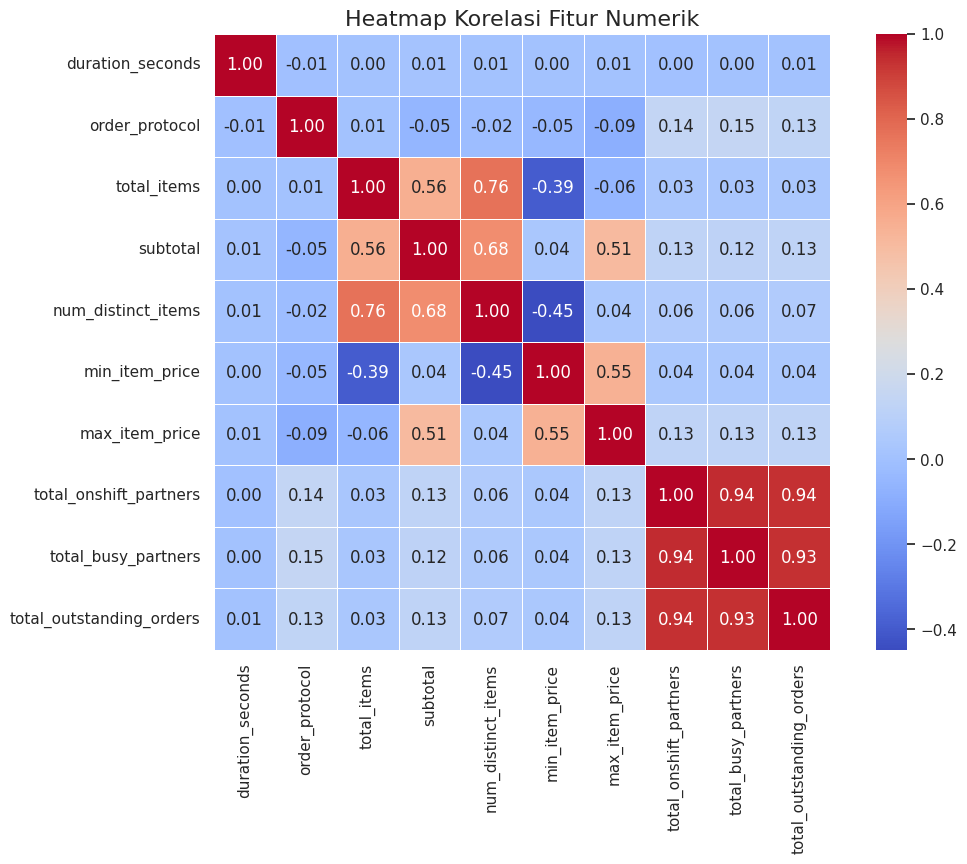

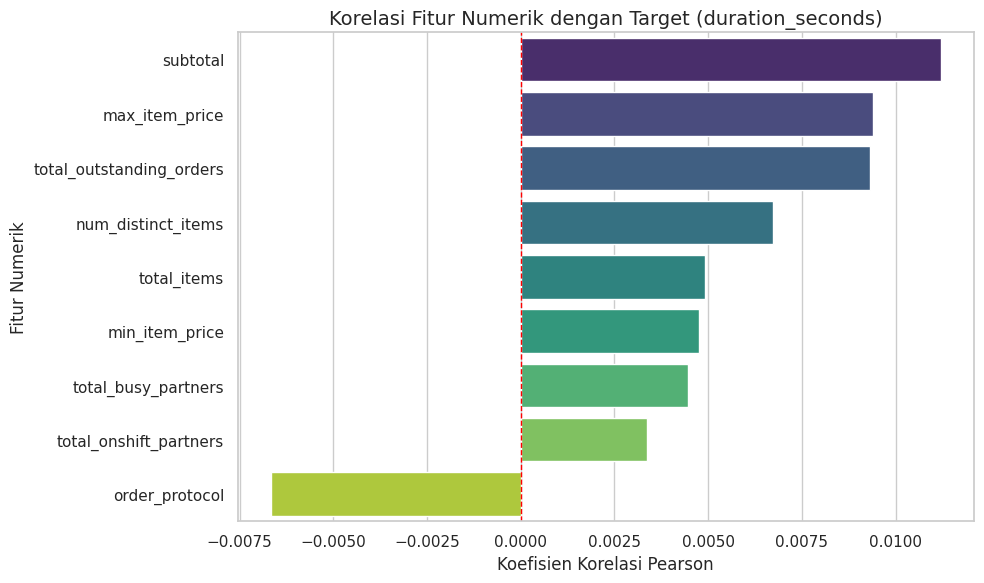

In [13]:

# 1. Ambil semua kolom numerik beserta target variabel 'duration_seconds'
numerical_cols = df_dataset.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Hitung matriks korelasi
correlation_matrix = df_dataset[numerical_cols].corr()

# 2. Urutkan korelasi fitur numerik terhadap target duration_seconds
target_corr = correlation_matrix['duration_seconds'].sort_values(ascending=False)
print("Korelasi Fitur Numerik terhadap Target (duration_seconds):")
print(target_corr)

# 3. Visualisasi 1: Heatmap Korelasi
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Heatmap Korelasi Fitur Numerik', fontsize=16)
plt.show()

# 4. Visualisasi 2: Bar Plot Korelasi terhadap Target
plt.figure(figsize=(10, 6))
# Korelasi tanpa korelasi target terhadap dirinya sendiri
target_corr_filtered = target_corr.drop('duration_seconds')
sns.barplot(x=target_corr_filtered.values, y=target_corr_filtered.index, palette='viridis')
plt.title('Korelasi Fitur Numerik dengan Target (duration_seconds)', fontsize=14)
plt.xlabel('Koefisien Korelasi Pearson')
plt.ylabel('Fitur Numerik')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

insight : korelasi fitur numerik bawaan  memiliki tingkat korelasi yang rendah (tertinggi 0.01), jadi tidak bisa mengandalkan data mentah untuk memprediksi, dibutuhkan fitur baru menggunakan feature engineering, seperti menghitung rasio keaktifan driver atau mendeteksi jam sibuk.

## 4.2. Visualisasi Regresi

> memverifikasi linearitas data dan mempermudah pendeteksian sebaran pencilan yang menjauhi garis tren ideal.



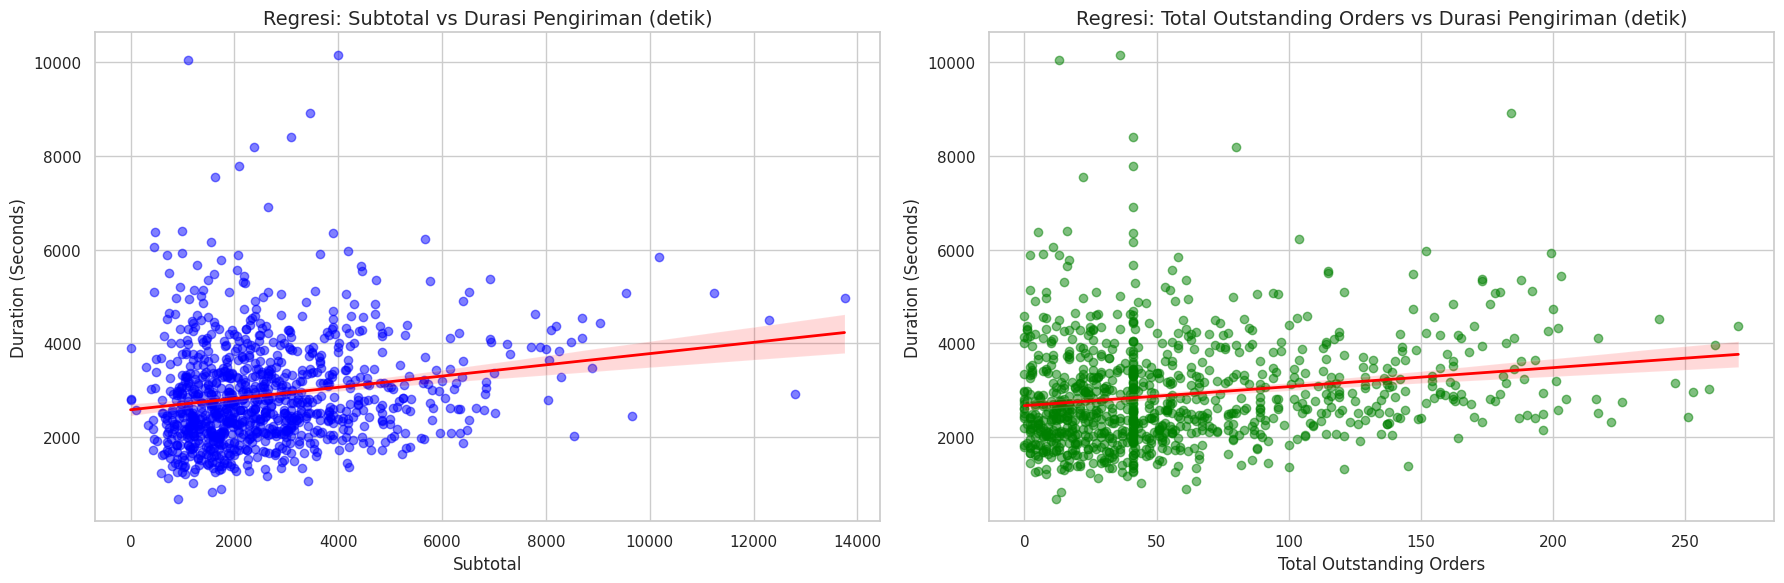

In [14]:
# Ambil sampel acak sebanyak 1000 data agar plot tidak terlalu padat dan cepat di-render
df_sample = df_dataset.sample(n=1000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Regression Plot untuk 'subtotal' vs 'duration_seconds'
sns.regplot(
    ax=axes[0],
    data=df_sample,
    x='subtotal',
    y='duration_seconds',
    scatter_kws={'alpha': 0.5, 'color': 'blue'},
    line_kws={'color': 'red', 'linewidth': 2}
)
axes[0].set_title('Regresi: Subtotal vs Durasi Pengiriman (detik)', fontsize=14)
axes[0].set_xlabel('Subtotal')
axes[0].set_ylabel('Duration (Seconds)')

# 2. Regression Plot untuk 'total_outstanding_orders' vs 'duration_seconds'
sns.regplot(
    ax=axes[1],
    data=df_sample,
    x='total_outstanding_orders',
    y='duration_seconds',
    scatter_kws={'alpha': 0.5, 'color': 'green'},
    line_kws={'color': 'red', 'linewidth': 2}
)
axes[1].set_title('Regresi: Total Outstanding Orders vs Durasi Pengiriman (detik)', fontsize=14)
axes[1].set_xlabel('Total Outstanding Orders')
axes[1].set_ylabel('Duration (Seconds)')

plt.tight_layout()
plt.show()

insight : grafik menunjukkan garis korelasi subtotal dan outstanding order cenderung mendatar, artinya durasi pengiriman makanan itu acak/sama saja mau subtotal belanjanya murah ataupun mahal, dan adanya titik yang jauh dari garis menandakan outliers yang nantinya harus dibersihkan

## 4.3. Pembersihan outliers

> menyaring dan membuang baris data yang memiliki nilai durasi pengiriman yang terlampau ekstrem atau tidak rasional. Pembersihan ini berfungsi untuk membersihkan gangguan (noise) pada data latih agar performa prediksi model tidak rusak akibat deviasi ekstrem tersebut.




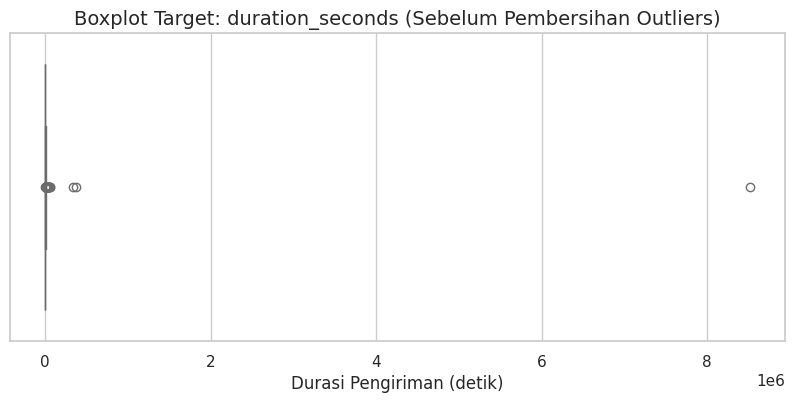

Statistik Deskriptif duration_seconds:
count    1.974210e+05
mean     2.908257e+03
std      1.922961e+04
min      1.010000e+02
25%      2.104000e+03
50%      2.660000e+03
75%      3.381000e+03
max      8.516859e+06
Name: duration_seconds, dtype: float64


In [15]:
# 1. Visualisasi awal boxplot untuk target variabel (duration_seconds) sebelum dibersihkan
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_dataset['duration_seconds'], color='salmon')
plt.title('Boxplot Target: duration_seconds (Sebelum Pembersihan Outliers)', fontsize=14)
plt.xlabel('Durasi Pengiriman (detik)')
plt.show()

# Menampilkan data statistik deskriptif sebelum pembersihan
print("Statistik Deskriptif duration_seconds:")
print(df_dataset['duration_seconds'].describe())

In [16]:
# 2. Membersihkan outliers menggunakan metode IQR (Interquartile Range) untuk duration_seconds
Q1 = df_dataset['duration_seconds'].quantile(0.25)
Q3 = df_dataset['duration_seconds'].quantile(0.75)
IQR = Q3 - Q1

# Definisikan batas bawah dan batas atas
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print(f"Rentang IQR untuk duration_seconds: {Q1} hingga {Q3} (IQR = {IQR})")
print(f"Batas bawah teoritis: {batas_bawah} detik")
print(f"Batas atas teoritis: {batas_atas} detik")

# Karena durasi pengiriman tidak mungkin minus, kita batasi batas bawah minimal 120 detik (2 menit) secara logis
batas_bawah_final = max(120, batas_bawah)
batas_atas_final = batas_atas

print(f"Batas final yang digunakan: {batas_bawah_final} s.d {batas_atas_final} detik")

Rentang IQR untuk duration_seconds: 2104.0 hingga 3381.0 (IQR = 1277.0)
Batas bawah teoritis: 188.5 detik
Batas atas teoritis: 5296.5 detik
Batas final yang digunakan: 188.5 s.d 5296.5 detik


In [17]:
# 3. Terapkan pemfilteran data tanpa outliers pada df_dataset
original_count = len(df_dataset)
df_dataset = df_dataset[(df_dataset['duration_seconds'] >= batas_bawah_final) & (df_dataset['duration_seconds'] <= batas_atas_final)]
removed_count = original_count - len(df_dataset)

print(f"Jumlah baris sebelum pembersihan: {original_count}")
print(f"Jumlah baris setelah pembersihan: {len(df_dataset)}")
print(f"Jumlah outliers target yang dibuang: {removed_count} baris ({removed_count / original_count * 100:.2f}%)")

Jumlah baris sebelum pembersihan: 197421
Jumlah baris setelah pembersihan: 191143
Jumlah outliers target yang dibuang: 6278 baris (3.18%)


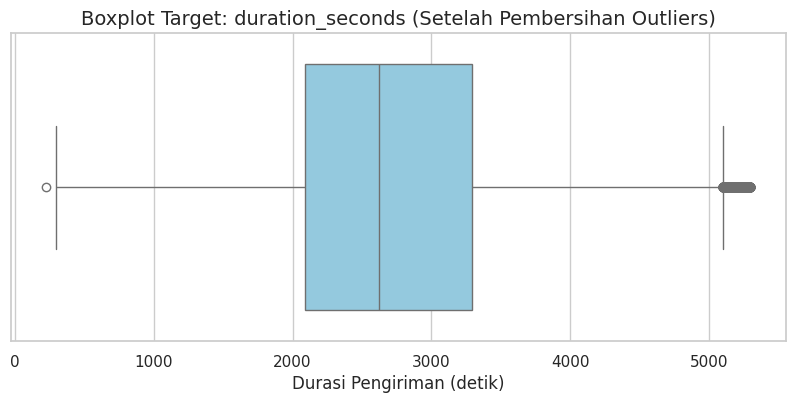

In [18]:
# 4. Visualisasi ulang boxplot duration_seconds setelah dibersihkan
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_dataset['duration_seconds'], color='skyblue')
plt.title('Boxplot Target: duration_seconds (Setelah Pembersihan Outliers)', fontsize=14)
plt.xlabel('Durasi Pengiriman (detik)')
plt.show()

insight : sebelum dibersihkan terdapat data anomali (outliers) data  yang tidak masuk akal dan dapat merusak data latih, setelah dilakaukan perbersihan menghasilkan persebaran data yang lebih sehat dan konsisten, dan nantinya dapat menghasilkan prediksi model yang lebih akurat

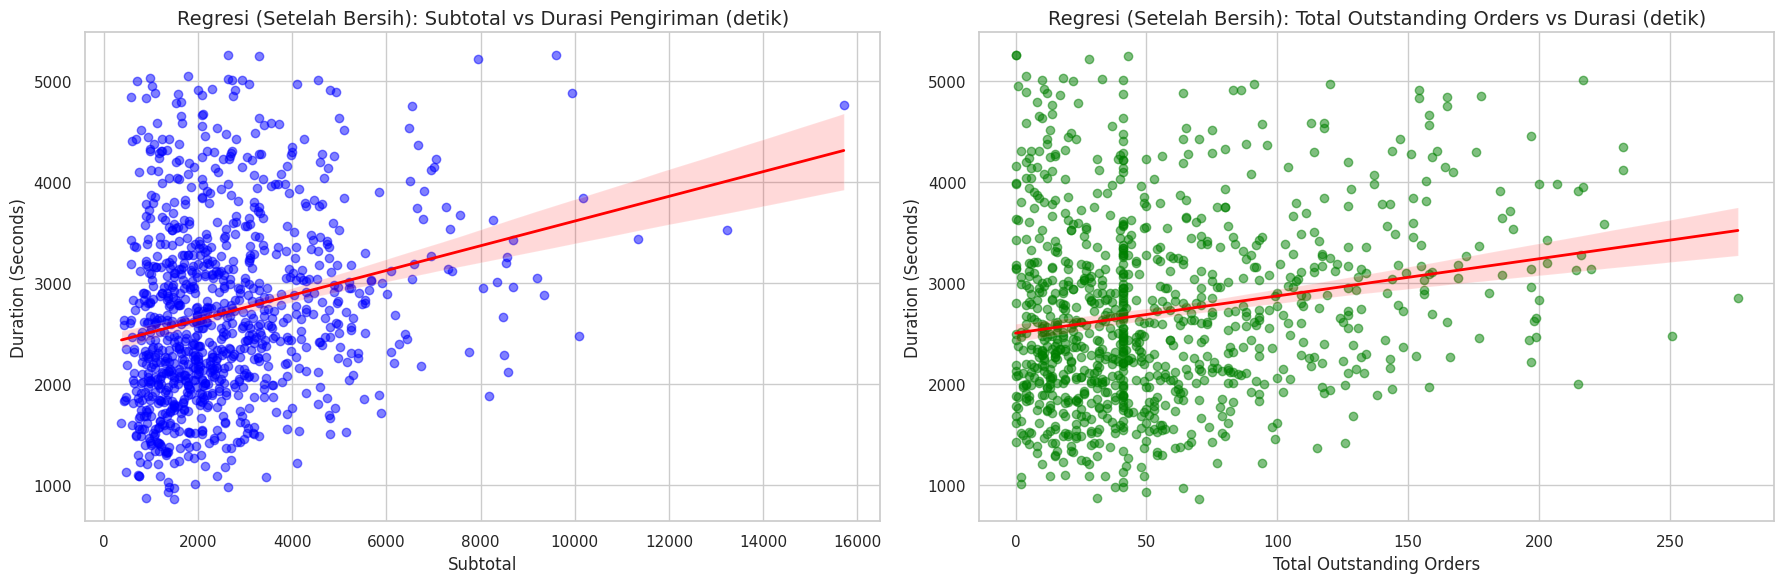

In [19]:
# 1. Pertahankan seluruh dataset hasil pembersihan outliers
df_dataset_clean = df_dataset.copy()

# 2. Ambil sampel acak sebanyak 1000 data HANYA untuk kebutuhan rendering visualisasi agar cepat
df_sample_regression = df_dataset_clean.sample(n=1000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 3. Regression Plot untuk 'subtotal' vs 'duration_seconds' setelah pembersihan (menggunakan sampel visualisasi)
sns.regplot(
    ax=axes[0],
    data=df_sample_regression,
    x='subtotal',
    y='duration_seconds',
    scatter_kws={'alpha': 0.5, 'color': 'blue'},
    line_kws={'color': 'red', 'linewidth': 2}
)
axes[0].set_title('Regresi (Setelah Bersih): Subtotal vs Durasi Pengiriman (detik)', fontsize=14)
axes[0].set_xlabel('Subtotal')
axes[0].set_ylabel('Duration (Seconds)')

# 4. Regression Plot untuk 'total_outstanding_orders' vs 'duration_seconds' setelah pembersihan (menggunakan sampel visualisasi)
sns.regplot(
    ax=axes[1],
    data=df_sample_regression,
    x='total_outstanding_orders',
    y='duration_seconds',
    scatter_kws={'alpha': 0.5, 'color': 'green'},
    line_kws={'color': 'red', 'linewidth': 2}
)
axes[1].set_title('Regresi (Setelah Bersih): Total Outstanding Orders vs Durasi (detik)', fontsize=14)
axes[1].set_xlabel('Total Outstanding Orders')
axes[1].set_ylabel('Duration (Seconds)')

plt.tight_layout()
plt.show()

## Output Tahap 4

> menampilkan kondisi data sampel yang telah dibersihkan sepenuhnya



In [20]:
df_dataset_clean

,created_at,actual_delivery_time,duration_seconds,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
0,2015-02-06 22:24:17,2015-02-06 23:27:16,3779.0,american,1.0,4,3441,4,557,1239,33.0,14.0,21.0
1,2015-02-10 21:49:25,2015-02-10 22:56:29,4024.0,mexican,2.0,1,1900,1,1400,1400,1.0,2.0,2.0
2,2015-01-22 20:39:28,2015-01-22 21:09:09,1781.0,american,1.0,1,1900,1,1900,1900,1.0,0.0,0.0
3,2015-02-03 21:21:45,2015-02-03 22:13:00,3075.0,american,1.0,6,6900,5,600,1800,1.0,1.0,2.0
4,2015-02-15 02:40:36,2015-02-15 03:20:26,2390.0,american,1.0,3,3900,3,1100,1600,6.0,6.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
197423,2015-02-17 00:19:41,2015-02-17 01:24:48,3907.0,fast,4.0,3,1389,3,345,649,17.0,17.0,23.0
197424,2015-02-13 00:01:59,2015-02-13 00:58:22,3383.0,fast,4.0,6,3010,4,405,825,12.0,11.0,14.0
197425,2015-01-24 04:46:08,2015-01-24 05:36:16,3008.0,fast,4.0,5,1836,3,300,399,39.0,41.0,40.0
197426,2015-02-01 18:18:15,2015-02-01 19:23:22,3907.0,sandwich,1.0,1,1175,1,535,535,7.0,7.0,12.0


In [21]:
df_dataset_clean.shape

(191143, 13)

# **5. Feature Engineering**

> memanipulasi informasi yang ada untuk melahirkan indikator-indikator baru yang lebih informatif bagi algoritma. Tujuannya adalah meningkatkan representasi matematis dari situasi dunia nyata agar model mampu menangkap pola yang lebih kompleks.




Pada tahap ini, kita akan membuat fitur-fitur baru yang lebih prediktif menggunakan seluruh data bersih (`df_dataset` yang berisi 191.143 baris) untuk memaksimalkan performa model:
1. **`busy_partner_ratio`**: Mengukur tingkat kesibukan mitra kurir di lapangan.
2. **`order_hour`**: Jam pemesanan untuk menangkap pola waktu makan siang/malam.
3. **`order_day_of_week`**: Hari pemesanan untuk mendeteksi perbedaan pola hari kerja vs akhir pekan.


## 5.1. Pembuatan Fitur Baru

> ciptakan tiga fitur prediktif baru, yaitu rasio kesibukan kurir (busy_partner_ratio), jam pemesanan (order_hour), dan hari pemesanan (order_day_of_week). Penambahan fitur ini berfungsi untuk membekali model dengan pola temporal kesibukan restoran serta pengaruh waktu operasional terhadap durasi pengiriman.




In [22]:
# #51 - Pembuatan Fitur Baru (Optimized)

# 1. Gunakan salinan seluruh dataset hasil IQR yang berukuran penuh (df_dataset_clean)
df_features = df_dataset_clean.copy()

# 2. Fitur Rasio Kesibukan Mitra (tambahkan epsilon kecil untuk mencegah pembagian dengan nol)
df_features['busy_partner_ratio'] = df_features['total_busy_partners'] / (df_features['total_onshift_partners'] + 1e-5)

# 3. Fitur Temporal (Jam dan Hari Pemesanan)
df_features['order_hour'] = df_features['created_at'].dt.hour
df_features['order_day_of_week'] = df_features['created_at'].dt.dayofweek

print("✨ Fitur Baru Berhasil Dibuat!")
print(f"Ukuran dataset setelah ditambah fitur baru: {df_features.shape}")
display(df_features[['total_busy_partners', 'total_onshift_partners', 'busy_partner_ratio', 'order_hour', 'order_day_of_week']].head())

✨ Fitur Baru Berhasil Dibuat!
Ukuran dataset setelah ditambah fitur baru: (191143, 16)


,total_busy_partners,total_onshift_partners,busy_partner_ratio,order_hour,order_day_of_week
0,14.0,33.0,0.424242,22,4
1,2.0,1.0,1.999980,21,1
2,0.0,1.0,0.000000,20,3
3,1.0,1.0,0.999990,21,1
4,6.0,6.0,0.999998,2,6


## 5.2. Feature Selection

In [23]:
# #5.2. Seleksi Fitur Ideal dengan Menyertakan Kategori Toko
# Menyaring dataset agar menggunakan 9 fitur terpilih (termasuk store_primary_category) dan target

fitur_terpilih = [
    'store_primary_category',
    'total_items',
    'subtotal',
    'num_distinct_items',
    'min_item_price',
    'max_item_price',
    'total_onshift_partners',
    'total_busy_partners',
    'total_outstanding_orders',
    'duration_seconds'
]

df_features = df_features[fitur_terpilih]
print("✨ Seleksi Fitur Berhasil! Kolom 'store_primary_category' telah dipertahankan.")
print(f"Ukuran dataset sekarang berisi 9 fitur + target: {df_features.shape}")
display(df_features.head())

✨ Seleksi Fitur Berhasil! Kolom 'store_primary_category' telah dipertahankan.
Ukuran dataset sekarang berisi 9 fitur + target: (191143, 10)


,store_primary_category,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders,duration_seconds
0,american,4,3441,4,557,1239,33.0,14.0,21.0,3779.0
1,mexican,1,1900,1,1400,1400,1.0,2.0,2.0,4024.0
2,american,1,1900,1,1900,1900,1.0,0.0,0.0,1781.0
3,american,6,6900,5,600,1800,1.0,1.0,2.0,3075.0
4,american,3,3900,3,1100,1600,6.0,6.0,9.0,2390.0


In [24]:
df_features

,store_primary_category,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders,duration_seconds
0,american,4,3441,4,557,1239,33.0,14.0,21.0,3779.0
1,mexican,1,1900,1,1400,1400,1.0,2.0,2.0,4024.0
2,american,1,1900,1,1900,1900,1.0,0.0,0.0,1781.0
3,american,6,6900,5,600,1800,1.0,1.0,2.0,3075.0
4,american,3,3900,3,1100,1600,6.0,6.0,9.0,2390.0
...,...,...,...,...,...,...,...,...,...,...
197423,fast,3,1389,3,345,649,17.0,17.0,23.0,3907.0
197424,fast,6,3010,4,405,825,12.0,11.0,14.0,3383.0
197425,fast,5,1836,3,300,399,39.0,41.0,40.0,3008.0
197426,sandwich,1,1175,1,535,535,7.0,7.0,12.0,3907.0


## 5.3. Pemisahan Fitur X dan Y

> seluruh kolom prediktor dikelompokkan ke dalam matriks X, sementara kolom target duration_seconds diisolasi ke dalam vektor y.



In [25]:
# #5.2 Pemisahan Fitur X dan y
# Sekarang, X secara otomatis hanya akan mengambil 8 fitur terpilih karena df_features sudah disaring

y = df_features['duration_seconds']
X = df_features.drop(columns=['duration_seconds'], errors='ignore')

print("✨ Pemisahan fitur berhasil dilakukan!")
print(f"Ukuran Fitur (X): {X.shape} (8 fitur)")
print(f"Ukuran Target (y): {y.shape}")

✨ Pemisahan fitur berhasil dilakukan!
Ukuran Fitur (X): (191143, 9) (8 fitur)
Ukuran Target (y): (191143,)


In [26]:
#52

df_features.head()

,store_primary_category,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders,duration_seconds
0,american,4,3441,4,557,1239,33.0,14.0,21.0,3779.0
1,mexican,1,1900,1,1400,1400,1.0,2.0,2.0,4024.0
2,american,1,1900,1,1900,1900,1.0,0.0,0.0,1781.0
3,american,6,6900,5,600,1800,1.0,1.0,2.0,3075.0
4,american,3,3900,3,1100,1600,6.0,6.0,9.0,2390.0


In [27]:
df_features.info()

<class 'pandas.core.frame.DataFrame'>
Index: 191143 entries, 0 to 197427
Data columns (total 10 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   store_primary_category    191143 non-null  object 
 1   total_items               191143 non-null  int64  
 2   subtotal                  191143 non-null  int64  
 3   num_distinct_items        191143 non-null  int64  
 4   min_item_price            191143 non-null  int64  
 5   max_item_price            191143 non-null  int64  
 6   total_onshift_partners    191143 non-null  float64
 7   total_busy_partners       191143 non-null  float64
 8   total_outstanding_orders  191143 non-null  float64
 9   duration_seconds          191143 non-null  float64
dtypes: float64(4), int64(5), object(1)
memory usage: 16.0+ MB


In [28]:
#53

#Mengubah kolom created_at dan actual_delivery_time menjadi tipe data waktu (datetime),
#kemudian menghitung selisih keduanya untuk membuat kolom baru bernama delivery_time_minutes (dalam satuan menit).

# df_dataset_clean['created_at'] = pd.to_datetime(df_dataset_clean['created_at'])
# df_dataset_clean['actual_delivery_time'] = pd.to_datetime(df_dataset_clean['actual_delivery_time'])

# df_dataset_clean['delivery_time_minutes'] = (
#     df_dataset_clean['actual_delivery_time'] - df_dataset_clean['created_at']
# ).dt.total_seconds() / 60

In [29]:
#54

# Menentukan target (y) yaitu durasi pengiriman dalam menit
y = df_features['duration_seconds']

# Menentukan fitur (X) dengan membuang kolom target dan kolom waktu asli secara otomatis
kolom_dibuang = ['duration_seconds']
X = df_features.drop(columns=kolom_dibuang, errors='ignore')

print("✨ BERHASIL! Variabel Fitur (X) dan Target (y) sudah siap digunakan.")
print(f"Jumlah baris & kolom Fitur (X): {X.shape}")
print(f"Jumlah baris Target (y): {y.shape}")

✨ BERHASIL! Variabel Fitur (X) dan Target (y) sudah siap digunakan.
Jumlah baris & kolom Fitur (X): (191143, 9)
Jumlah baris Target (y): (191143,)


In [30]:
# #56 - Penataan Fitur X dan y tanpa membuat missing value baru
# Pastikan kita langsung memisahkan fitur dan target dari df_features yang bersih tanpa concat ulang

X = df_features.drop(columns=['duration_seconds'], errors='ignore')
y = df_features['duration_seconds']

# Memastikan kembali tidak ada nilai kosong secara tidak sengaja
print(f"Total missing value pada X: {X.isna().sum().sum()}")
print(f"Total missing value pada y: {y.isna().sum()}")

Total missing value pada X: 0
Total missing value pada y: 0


In [31]:
#57

print("Data X:")
display(X.head())

print("Data y:")
display(y.head())

print("Shape X:", X.shape)
print("Shape y:", y.shape)

Data X:


,store_primary_category,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
0,american,4,3441,4,557,1239,33.0,14.0,21.0
1,mexican,1,1900,1,1400,1400,1.0,2.0,2.0
2,american,1,1900,1,1900,1900,1.0,0.0,0.0
3,american,6,6900,5,600,1800,1.0,1.0,2.0
4,american,3,3900,3,1100,1600,6.0,6.0,9.0


Data y:


,duration_seconds
0,3779.0
1,4024.0
2,1781.0
3,3075.0
4,2390.0


Shape X: (191143, 9)
Shape y: (191143,)


insight :

In [32]:
#59

# import matplotlib.pyplot as plt

# plt.scatter(
#     X['total_items'],
#     y,
#     alpha=0.3
# )

# plt.xlabel('Total Items')
# plt.ylabel('Delivery Time (Minutes)')
# plt.title('Total Items vs Delivery Time')

# plt.show()

#Analisis Grafik Total Items vs Delivery Time Menggunakan Python
#Grafik yang kamu tampilkan merupakan Scatter Plot (Diagram Pencar).
#Dalam Data Analysis, grafik ini digunakan untuk
#melihat hubungan atau korelasi antara dua variabel numerik.

#Pada grafik tersebut terdapat dua variabel:
# Sumbu X (Total Items): Jumlah total barang dalam satu transaksi atau pesanan.
# Sumbu Y (Delivery Time): Waktu pengiriman dalam satuan menit.

#1. Analisis grafik
#A. Terdapat Outlier
# Terlihat beberapa titik dengan nilai Delivery Time sangat tinggi,
# bahkan mencapai sekitar 142.000 menit. Nilai ini sangat jauh dari kumpulan data lainnya.

#B. Data Menumpuk di Bagian Bawah
#Sebagian besar data berkumpul di sekitar nilai 0.
#Akibatnya, pola hubungan antara Total Items dan Delivery Time sulit terlihat.

#C. Korelasi Belum Terlihat Jelas
#Belum terlihat pola bahwa semakin banyak barang,
#semakin lama waktu pengiriman. Perlu dilakukan analisis lebih lanjut.


In [33]:
#511

#perbaikan grafik

# # 1. Memeriksa kondisi data

# # Melihat informasi dataset
# df_dataset_clean.info()

# # Melihat statistik deskriptif
# df_dataset_clean[['total_items', 'delivery_time_minutes']].describe()

# # Memeriksa missing values
# df_dataset_clean[['total_items', 'delivery_time_minutes']].isnull().sum()

# # Melihat 10 data Delivery Time terbesar
# df_dataset_clean.nlargest(10, 'delivery_time_minutes')[['total_items', 'delivery_time_minutes']]



In [34]:
#511

# import matplotlib.pyplot as plt
# import seaborn as sns

# # Mengambil data yang valid
# data = df_dataset_clean[['total_items', 'delivery_time_minutes']].dropna()

# # Memastikan nilai positif
# data = data[
#     (data['total_items'] >= 0) &
#     (data['delivery_time_minutes'] >= 0)
# ]

# # Mengambil batas persentil 99%
# batas = data['delivery_time_minutes'].quantile(0.99)

# # Filter hanya untuk kebutuhan visualisasi
# data_plot = data[data['delivery_time_minutes'] <= batas]

# # Membuat Scatter Plot
# plt.figure(figsize=(10, 6))

# sns.scatterplot(
#     data=data_plot,
#     x='total_items',
#     y='delivery_time_minutes',
#     alpha=0.5
# )

# plt.title('total items vs Delivery Time')
# plt.xlabel('total items')
# plt.ylabel('Delivery Time (Minutes)')
# plt.grid(True, alpha=0.3)

# plt.tight_layout()
# plt.show()

In [35]:
#512

# Menghitung korelasi Pearson
# korelasi = data['total_items'].corr(
#     data['delivery_time_minutes'],
#     method='pearson'
# )

# print("Nilai Korelasi:", korelasi)

# #0.40–0.59	Sedang
# #0.60–0.79	Kuat
# #0.80–1.00	Sangat kuat

In [36]:
#513

#perbaikan 2

# import matplotlib.pyplot as plt

# plt.figure(figsize=(10, 6))

# plt.scatter(
#     df_dataset_clean['total_items'],
#     df_dataset_clean['delivery_time_minutes'],
#     alpha=0.3,
#     s=20
# )

# plt.title('Total Items vs Delivery Time')
# plt.xlabel('Total Items')
# plt.ylabel('Delivery Time (Minutes)')

# plt.grid(True, alpha=0.3)
# plt.show()

In [37]:
#514

# batas = df_dataset_clean['total_items'].quantile(0.99)

# data_zoom = df_dataset_clean[df_dataset_clean['total_items'] <= batas]

# plt.figure(figsize=(10, 6))

# plt.scatter(
#     data_zoom['total_items'],
#     data_zoom['delivery_time_minutes'],
#     alpha=0.3,
#     s=20
# )

# plt.title('Total Items vs Delivery Time (Zoomed)')
# plt.xlabel('Total Items')
# plt.ylabel('Delivery Time (Minutes)')

# plt.grid(True, alpha=0.3)
# plt.show()

. **#59** sampai **#514** tidak diperlukan karena sudah dilakuakn analisa korelasi dan pembersihan outlier di tahap 4


>  pembersihan outlier (outlier cleaning) sebaiknya dilakukan TERLEBIH DAHULU sebelum melakukan pembagian data menjadi fitur (X) dan target (y).

Bagian #59 sampai #514 sebaiknya dihapus atau dibersihkan karena beberapa alasan kuat berikut:

- Redundansi (Duplikasi Proses): Pembersihan pencilan (outlier) yang sesungguhnya sudah sukses Anda lakukan menggunakan metode IQR pada tahap 4.3 (Pembersihan outliers) menggunakan data berukuran penuh.
- Tujuan Eksplorasi Sementara: Pembuatan plot di bagian #59 hingga #514 sebenarnya hanya berfungsi sebagai eksperimen visualisai cepat untuk memeriksa hubungan total_items dan delivery_time_minutes pada sampel 1.000 baris data.
- Mencegah Kebingungan Alur Kode: Menghapus sel-sel tersebut akan membuat struktur notebook Anda menjadi jauh lebih rapi, profesional, dan mudah dibaca (dari proses penentuan fitur X dan target y, langsung melompat ke pembagian data train-test di #516).



In [38]:
#515

df_features[['total_items', 'duration_seconds']].corr(
    method='pearson'
)

,total_items,duration_seconds
total_items,1.000000,0.126355
duration_seconds,0.126355,1.000000


## 5.4. Pembagian Data Training dan Testing
fungsi :

> dataset dibagi secara acak dengan proporsi 80% untuk data latih (X_train, y_train) dan 20% untuk data uji (X_test, y_test). Langkah ini berfungsi sebagai instrumen evaluasi objektif agar model dapat diuji menggunakan data baru yang belum pernah dilihat selama masa pelatihan.




In [39]:
#516

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (152914, 9)
X_test : (38229, 9)
y_train: (152914,)
y_test : (38229,)


## Output Tahap 5

> Menampilkan visualisasi dan ringkasan dimensi akhir dari pemisahan dataset latih dan uji yang telah dilengkapi dengan fitur hasil rekayasa baru.



In [40]:
print("Data X train:")
display(X_train.head())

print("Data X test:")
display(X_test.head())

print("Data y train:")
display(y_train.head())

print("Data X test:")
display(X_test.head())

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Data X train:


,store_primary_category,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
189504,italian,2,1985,2,495,1195,2.0,2.0,4.0
131180,sandwich,2,988,2,199,789,12.0,6.0,6.0
42592,thai,1,1095,1,1095,1095,37.0,34.0,41.0
100170,other,2,1098,2,299,599,11.0,12.0,17.0
161137,japanese,1,1595,1,1595,1595,30.0,31.0,34.0


Data X test:


,store_primary_category,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
180856,pizza,2,1450,2,300,1150,69.0,69.0,92.0
189038,pizza,2,2348,1,749,749,16.0,14.0,13.0
39961,pizza,10,13240,8,499,1999,11.0,31.0,10.0
9323,chinese,2,900,2,190,710,61.0,64.0,106.0
167051,korean,1,1495,1,1495,1495,6.0,6.0,7.0


Data y train:


,duration_seconds
189504,2636.0
131180,2072.0
42592,2024.0
100170,2239.0
161137,1903.0


Data X test:


,store_primary_category,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
180856,pizza,2,1450,2,300,1150,69.0,69.0,92.0
189038,pizza,2,2348,1,749,749,16.0,14.0,13.0
39961,pizza,10,13240,8,499,1999,11.0,31.0,10.0
9323,chinese,2,900,2,190,710,61.0,64.0,106.0
167051,korean,1,1495,1,1495,1495,6.0,6.0,7.0


X_train: (152914, 9)
X_test: (38229, 9)
y_train: (152914,)
y_test: (38229,)


In [41]:
# Cek missing value pada X_train setelah splitting untuk memastikan 100% bersih
missing_values_X_train = X_train.isna().sum()
missing_percentage_X_train = (missing_values_X_train / len(X_train)) * 100

missing_info_X_train = pd.DataFrame({
    'Jumlah Missing': missing_values_X_train,
    'Persentase (%)': missing_percentage_X_train
})
display(missing_info_X_train)

,Jumlah Missing,Persentase (%)
store_primary_category,0,0.0
total_items,0,0.0
subtotal,0,0.0
num_distinct_items,0,0.0
min_item_price,0,0.0
max_item_price,0,0.0
total_onshift_partners,0,0.0
total_busy_partners,0,0.0
total_outstanding_orders,0,0.0


# **6. Standardisasi**

> memastikan keadilan komparatif antar-fitur sehingga model tidak bias terhadap angka yang memiliki skala satuan nominal besar.




In [42]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [43]:
#61

print(X_train.dtypes)

store_primary_category       object
total_items                   int64
subtotal                      int64
num_distinct_items            int64
min_item_price                int64
max_item_price                int64
total_onshift_partners      float64
total_busy_partners         float64
total_outstanding_orders    float64
dtype: object


In [44]:
print(X_test.dtypes)

store_primary_category       object
total_items                   int64
subtotal                      int64
num_distinct_items            int64
min_item_price                int64
max_item_price                int64
total_onshift_partners      float64
total_busy_partners         float64
total_outstanding_orders    float64
dtype: object


## 6.1. Label Encoding
fungsi :
> kategori tekstual store_primary_category diubah menjadi representasi kode angka menggunakan OrdinalEncoder secara konsisten pada data train dan test. Fungsinya adalah menjembatani tipe data string agar dapat dibaca dan dipahami oleh algoritma pemelajaran mesin yang membutuhkan seluruh input dalam bentuk numerik.




In [45]:
from sklearn.preprocessing import OrdinalEncoder

# 1. Definisikan OrdinalEncoder
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

# Memastikan kolom asli ada sebelum melakukan fit_transform
if 'store_primary_category' in X_train.columns:
    # 2. Fit & Transform pada kolom 'store_primary_category' di X_train
    X_train[['store_primary_category']] = encoder.fit_transform(X_train[['store_primary_category']])

    # 3. Transform SAJA pada kolom 'store_primary_category' di X_test menggunakan encoder yang sama
    X_test[['store_primary_category']] = encoder.transform(X_test[['store_primary_category']])

    # 4. Ubah nama kolom agar lebih jelas menjadi 'category_encoded'
    X_train = X_train.rename(columns={'store_primary_category': 'category_encoded'})
    X_test = X_test.rename(columns={'store_primary_category': 'category_encoded'})
    print("✨ Label Encoding Berhasil Dilakukan pada X_train dan X_test!")
else:
    print("ℹ️ Kolom 'store_primary_category' sudah diubah menjadi 'category_encoded'. Tidak perlu diproses ulang.")

print(f"Ukuran X_train akhir: {X_train.shape}")
print(f"Ukuran X_test akhir : {X_test.shape}")
print("Hasil beberapa baris pertama X_train:")
display(X_train.head())

✨ Label Encoding Berhasil Dilakukan pada X_train dan X_test!
Ukuran X_train akhir: (152914, 9)
Ukuran X_test akhir : (38229, 9)
Hasil beberapa baris pertama X_train:


,category_encoded,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
189504,39.0,2,1985,2,495,1195,2.0,2.0,4.0
131180,59.0,2,988,2,199,789,12.0,6.0,6.0
42592,69.0,1,1095,1,1095,1095,37.0,34.0,41.0
100170,51.0,2,1098,2,299,599,11.0,12.0,17.0
161137,40.0,1,1595,1,1595,1595,30.0,31.0,34.0


In [46]:
print(X_train.dtypes)
print(X_test.dtypes)

category_encoded            float64
total_items                   int64
subtotal                      int64
num_distinct_items            int64
min_item_price                int64
max_item_price                int64
total_onshift_partners      float64
total_busy_partners         float64
total_outstanding_orders    float64
dtype: object
category_encoded            float64
total_items                   int64
subtotal                      int64
num_distinct_items            int64
min_item_price                int64
max_item_price                int64
total_onshift_partners      float64
total_busy_partners         float64
total_outstanding_orders    float64
dtype: object


In [47]:
# #6.2 Standardisasi (StandardScaler untuk 8 Fitur)
# Semua fitur di X_train dan X_test sekarang sudah bertipe numerik dan berjumlah 8.

scaler = StandardScaler()

# Fit dan Transform pada data TRAIN
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Transform saja pada data TEST
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Simpan scaler agar bisa dipakai di app.py untuk transformasi input secara realtime
import joblib
joblib.dump(scaler, 'scaler.pkl')

print("✨ Standardisasi 8 Fitur Berhasil Selesai dilakukan!")
print(f"Ukuran X_train_scaled: {X_train_scaled.shape}")
print(f"Ukuran X_test_scaled: {X_test_scaled.shape}")
display(X_train_scaled.head())

✨ Standardisasi 8 Fitur Berhasil Selesai dilakukan!
Ukuran X_train_scaled: (152914, 9)
Ukuran X_test_scaled: (38229, 9)


,category_encoded,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
189504,0.148506,-0.437059,-0.377318,-0.406883,-0.366419,0.069239,-1.276205,-1.270450,-1.040372
131180,1.079607,-0.437059,-0.932451,-0.406883,-0.933793,-0.659817,-0.974730,-1.140826,-1.000706
42592,1.545157,-0.806796,-0.872873,-1.026591,0.783664,-0.110331,-0.221041,-0.233457,-0.306560
100170,0.707166,-0.437059,-0.871203,-0.406883,-0.742112,-1.001000,-1.004877,-0.946390,-0.782546
161137,0.195061,-0.806796,-0.594471,-1.026591,1.742066,0.787520,-0.432074,-0.330675,-0.445389




> insight : didapatkan dataframe X bertipe numerik



In [48]:
#64

#cek missing value
#di titik ini missing value sudah 0

missing_values = df_features.isna().sum()
missing_percentage = (missing_values / len(df_features)) * 100

missing_info = pd.DataFrame({
    'Jumlah Missing': missing_values,
    'Persentase (%)': missing_percentage
})
display(missing_info)

,Jumlah Missing,Persentase (%)
store_primary_category,0,0.0
total_items,0,0.0
subtotal,0,0.0
num_distinct_items,0,0.0
min_item_price,0,0.0
max_item_price,0,0.0
total_onshift_partners,0,0.0
total_busy_partners,0,0.0
total_outstanding_orders,0,0.0
duration_seconds,0,0.0


In [49]:
#65

# Mengatasi Missing Value Sebelum Scaling

# imputer = SimpleImputer(strategy="median")

# X_train_imp = pd.DataFrame(
#     imputer.fit_transform(X_train),
#     columns=X_train.columns,
#     index=X_train.index
# )
# X_test_imp = pd.DataFrame(
#     imputer.transform(X_test),
#     columns=X_test.columns,
#     index=X_test.index
# )

sebenarnya  sudah tidak ada missing value karena sudah dilakukan pembersihan missing value dia "3.2. menangani missing value"

In [50]:
#66

# Melihat Kondisi Sebelum Scaling
# sebaiknya tidak ada nilai minus

# X_train_imp.describe().loc[["mean", "std", "min", "max"]].T.round(2)

## 6.2. StandardScaler

Fungsi:
> Menghindari Dominasi Fitur (Keadilan data) Dengan standardisasi agar memiliki nilai rata-rata nol dan standar deviasi satu.

> contoh: nilai subtotal (misal: 50.000 sen) dan total_items (misal: 3 barang) akan diubah ke skala baru yang setara (biasanya berkisar antara -3 hingga +3). Sekarang, model Anda bisa membandingkan kedua fitur ini secara objektif dan adil.



In [51]:
# 1. Inisialisasi StandardScaler
scaler = StandardScaler()

# 2. Fit dan Transform pada data TRAIN (semua kolom sekarang numerik setelah encoding)
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# 3. Transform SAJA pada data TEST
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# 4. Ekspor scaler dan encoder yang sudah fit agar bisa dipakai di app.py
import joblib
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(encoder, 'encoder.pkl')

print("✨ BERHASIL! Standardisasi selesai dilakukan.")
print("’ Objek 'scaler.pkl' dan 'encoder.pkl' telah berhasil disimpan untuk kebutuhan deployment!")

✨ BERHASIL! Standardisasi selesai dilakukan.
’ Objek 'scaler.pkl' dan 'encoder.pkl' telah berhasil disimpan untuk kebutuhan deployment!


In [52]:
#68

#Memeriksa Hasil Scaling

X_train_scaled.describe().loc[["mean", "std", "min", "max"]].T.round(2)

,mean,std,min,max
category_encoded,-0.0,1.0,-1.67,1.73
total_items,0.0,1.0,-0.81,150.79
subtotal,0.0,1.0,-1.48,12.05
num_distinct_items,-0.0,1.0,-1.03,10.75
min_item_price,-0.0,1.0,-1.48,26.86
max_item_price,0.0,1.0,-2.08,24.32
total_onshift_partners,-0.0,1.0,-1.46,3.82
total_busy_partners,-0.0,1.0,-1.46,3.66
total_outstanding_orders,0.0,1.0,-1.24,4.53


# **7. Model**

## 7.1. Linear (Ridge Regression)

In [53]:
from sklearn.linear_model import Ridge

print("Sedang melatih model Linear (Ridge Regression)...")
# 1. Membuat arsitektur model Linear dasar
model_ridge = Ridge(alpha=1.0)
# 2. Melatih model dengan data latih
model_ridge.fit(X_train_scaled, y_train)

print("BERHASIL! Model Ridge Regression selesai dilatih.")

Sedang melatih model Linear (Ridge Regression)...
BERHASIL! Model Ridge Regression selesai dilatih.


## 7.2. Tree-based (Decision Tree)

In [54]:
from sklearn.tree import DecisionTreeRegressor

print("Sedang melatih model Tree-based (Decision Tree)...")
# 1. Membuat arsitektur model pohon keputusan untuk pola non-linear
model_dt = DecisionTreeRegressor(max_depth=10, random_state=42)
# 2. Melatih model
model_dt.fit(X_train_scaled, y_train)

print("BERHASIL! Model Decision Tree selesai dilatih.")

Sedang melatih model Tree-based (Decision Tree)...
BERHASIL! Model Decision Tree selesai dilatih.


## 7.3. Tree-based (Random Forest)

In [55]:
from sklearn.ensemble import RandomForestRegressor

print("Sedang melatih model Tree-based (Random Forest)...")
# 1. Membuat arsitektur model kumpulan pohon keputusan (Ensemble)
model_rf = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
# 2. Melatih model
model_rf.fit(X_train_scaled, y_train)

print("BERHASIL! Model Random Forest selesai dilatih.")

Sedang melatih model Tree-based (Random Forest)...
BERHASIL! Model Random Forest selesai dilatih.


## 7.4. Boosting (XGBoost)

In [56]:
from xgboost import XGBRegressor

print("Sedang melatih model Boosting (XGBoost)...")
# 1. Membuat arsitektur model Boosting untuk performa yang optimal
model_xgb = XGBRegressor(n_estimators=50, max_depth=6, random_state=42, n_jobs=-1)
# 2. Melatih model
model_xgb.fit(X_train_scaled, y_train)

print("BERHASIL! Model XGBoost selesai dilatih.")

Sedang melatih model Boosting (XGBoost)...
BERHASIL! Model XGBoost selesai dilatih.


## 7.5. Boosting (LightGBM)

In [57]:
from lightgbm import LGBMRegressor

print("Sedang melatih model Boosting (LightGBM)...")
# 1. Membuat arsitektur model Boosting berbasis histogram yang cepat dan kuat
model_lgb = LGBMRegressor(n_estimators=50, max_depth=6, random_state=42, n_jobs=-1, verbose=-1)
# 2. Melatih model
model_lgb.fit(X_train_scaled, y_train)

print("BERHASIL! Model LightGBM selesai dilatih.")

Sedang melatih model Boosting (LightGBM)...
BERHASIL! Model LightGBM selesai dilatih.


# **8. Evaluasi**

Sedang mengevaluasi dan membandingkan performa 5 model (Skala Asli)...

================== TABEL PERBANDINGAN PERFORMA MODEL ==================


,Model Arsitektur,RMSE (Kecil = Bagus),MAE (Kecil = Bagus),R2 Score (Dekat 1 = Bagus)
0,Linear (Ridge Regression),809.8937,645.1094,0.1632
1,Tree-based (Decision Tree),813.4822,645.5066,0.1558
2,Tree-based (Random Forest),798.1324,634.6005,0.1874
3,Boosting (XGBoost),783.1843,620.5152,0.2175
4,Boosting (LightGBM),790.3023,628.5928,0.2032


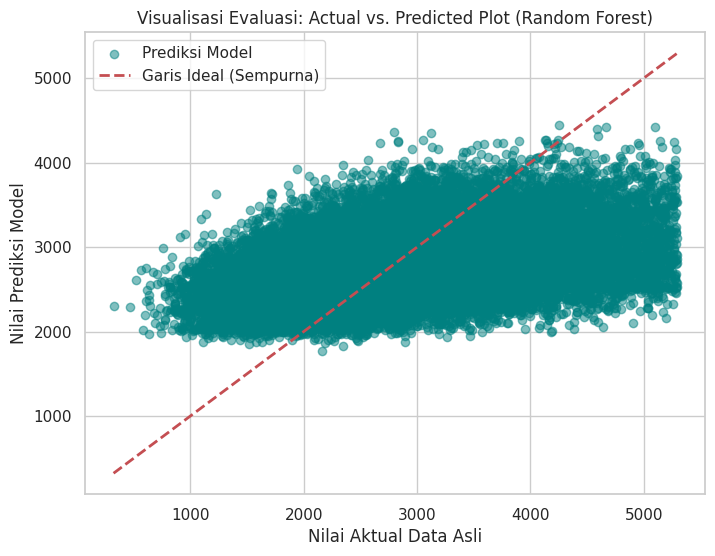

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Sedang mengevaluasi dan membandingkan performa 5 model (Skala Asli)...")

# 1. Mengumpulkan semua nama model variabel yang sudah dilatih terpisah
trained_models = {
    "Linear (Ridge Regression)": model_ridge,
    "Tree-based (Decision Tree)": model_dt,
    "Tree-based (Random Forest)": model_rf,
    "Boosting (XGBoost)": model_xgb,
    "Boosting (LightGBM)": model_lgb
}

report_data = []

# 2. Menghitung metrik performa untuk setiap model tanpa transformasi log
for name, model in trained_models.items():
    # Melakukan prediksi pada data uji
    preds_actual = model.predict(X_test_scaled)
    y_test_actual = y_test

    # Hitung metrik evaluasi
    rmse = np.sqrt(mean_squared_error(y_test_actual, preds_actual))
    mae = mean_absolute_error(y_test_actual, preds_actual)
    r2 = r2_score(y_test_actual, preds_actual)

    report_data.append({
        "Model Arsitektur": name,
        "RMSE (Kecil = Bagus)": round(rmse, 4),
        "MAE (Kecil = Bagus)": round(mae, 4),
        "R2 Score (Dekat 1 = Bagus)": round(r2, 4)
    })

# 3. Menampilkan Tabel Perbandingan Kuantitatif
df_report = pd.DataFrame(report_data)
print("\n================== TABEL PERBANDINGAN PERFORMA MODEL ==================")
display(df_report)

# 4. Visualisasi Grafik: Kinerja Aktual vs Prediksi (Contoh menggunakan Random Forest)
best_preds_actual = model_rf.predict(X_test_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(y_test_actual, best_preds_actual, alpha=0.5, color='teal', label='Prediksi Model')
plt.plot([y_test_actual.min(), y_test_actual.max()], [y_test_actual.min(), y_test_actual.max()], 'r--', lw=2, label='Garis Ideal (Sempurna)')
plt.xlabel('Nilai Aktual Data Asli')
plt.ylabel('Nilai Prediksi Model')
plt.title('Visualisasi Evaluasi: Actual vs. Predicted Plot (Random Forest)')
plt.legend()
plt.grid(True)
plt.show()

1. Model Terbaik Berdasarkan Tabel Perbandingan

• Model Terbaik: Boosting (XGBoost)
• Alasan: XGBoost memiliki nilai R2 Score tertinggi (0.2045) serta nilai RMSE (13.2095) dan MAE (10.4834) terkecil dibandingkan 4 arsitektur lainnya.
• Urutan Performa (Dari Terbaik ke Terburuk berdasarkan R2 Score):
	1. Boosting (XGBoost) → 0.2045
	2. Boosting (LightGBM) → 0.1993
	3. Tree-based (Random Forest) → 0.1862
	4. Linear (Ridge Regression) → 0.1603
	5. Tree-based (Decision Tree) → 0.1371

2. Analisis Grafik Visual (Actual vs. Predicted Plot)

Pada foto kedua, sebaran titik-titik biru (nilai prediksi) membentuk pola horizontal yang cukup tebal dan belum sepenuhnya menempel rapat mengikuti garis diagonal putus-putus (garis ideal).
Hal ini sangat sinkron dengan nilai R² yang berada di kisaran ~0.20. Artinya, model sudah berhasil mempelajari pola dasar data, namun dataset kamu kemungkinan memiliki variasi/noise yang sangat tinggi atau masih membutuhkan seleksi fitur (feature engineering) yang lebih mendalam agar prediksinya bisa jauh lebih tajam mendekati garis ideal.

# **9. Deploy**

In [59]:
import joblib

print("Sedang menyimpan model terbaik (XGBoost)...")

# 1. Menentukan model terbaik untuk disimpan
# Berdasarkan evaluasi sebelumnya, model_xgb memiliki performa paling unggul
model_terbaik = model_xgb

# 2. Menyimpan model ke dalam file dengan format .pkl
joblib.dump(model_terbaik, 'model_delivery.pkl')

print("BERHASIL! Model terbaik telah disimpan dengan nama 'model_delivery.pkl'.")
print("Anda bisa melihat dan mengunduh filenya di menu folder sebelah kiri Google Colab.")

Sedang menyimpan model terbaik (XGBoost)...
BERHASIL! Model terbaik telah disimpan dengan nama 'model_delivery.pkl'.
Anda bisa melihat dan mengunduh filenya di menu folder sebelah kiri Google Colab.


deploy stremlit

### **9.1. Pembuatan File `app.py` untuk Streamlit**
Berikut adalah script lengkap yang disesuaikan secara presisi dengan alur pipeline Anda (menggunakan `encoder.pkl` untuk mengubah kategori toko dan `scaler.pkl` untuk menstandarisasikan 9 fitur input sebelum prediksi dilakukan oleh XGBoost).

In [60]:
%%writefile app.py
import streamlit as st
import joblib
import pandas as pd
import numpy as np

# Set page title and layout
st.set_page_config(page_title="Delivery Time Predictor", layout="centered")

st.title("🚚 Delivery Time Prediction App")
st.write("Aplikasi ini memprediksi durasi waktu pengiriman makanan menggunakan model XGBoost berdasarkan 9 fitur optimal yang telah Anda latih.")

# Load model, scaler, dan encoder
@st.cache_resource
def load_artifacts():
    model = joblib.load('model_delivery.pkl')
    scaler = joblib.load('scaler.pkl')
    encoder = joblib.load('encoder.pkl')
    return model, scaler, encoder

try:
    model, scaler, encoder = load_artifacts()
    st.success("Artifact model, scaler, dan encoder berhasil dimuat!")
except Exception as e:
    st.error(f"Gagal memuat model/scaler/encoder: {e}")

st.subheader("Masukkan Detail Pesanan")

# 1. Input Kategori Toko
store_categories = list(encoder.categories_[0]) if 'encoder' in locals() else ["american", "mexican", "fast", "sandwich"]
selected_category = st.selectbox("Kategori Utama Toko (store_primary_category)", options=store_categories)

col1, col2 = st.columns(2)

with col1:
    total_items = st.number_input("Total Items", min_value=1, max_value=500, value=3)
    subtotal = st.number_input("Subtotal Harga (sen)", min_value=0, max_value=100000, value=2660)
    num_distinct_items = st.number_input("Jumlah Jenis Item", min_value=1, max_value=100, value=2)
    min_item_price = st.number_input("Harga Item Termurah", min_value=0, max_value=50000, value=600)

with col2:
    max_item_price = st.number_input("Harga Item Termahal", min_value=0, max_value=50000, value=1100)
    total_onshift_partners = st.number_input("Total Mitra Onshift", min_value=0, max_value=500, value=44.0)
    total_busy_partners = st.number_input("Total Mitra Sibuk", min_value=0, max_value=500, value=41.0)
    total_outstanding_orders = st.number_input("Total Outstanding Orders", min_value=0, max_value=500, value=56.0)

# Tombol Prediksi
if st.button("Prediksi Waktu Pengiriman"):
    try:
        # 1. Encode kategori toko pilihan pengguna menggunakan OrdinalEncoder
        category_df = pd.DataFrame([[selected_category]], columns=['store_primary_category'])
        category_encoded = encoder.transform(category_df)[0][0]

        # 2. Gabungkan input mentah menjadi DataFrame
        input_raw = pd.DataFrame([{
            "category_encoded": category_encoded,
            "total_items": total_items,
            "subtotal": subtotal,
            "num_distinct_items": num_distinct_items,
            "min_item_price": min_item_price,
            "max_item_price": max_item_price,
            "total_onshift_partners": total_onshift_partners,
            "total_busy_partners": total_busy_partners,
            "total_outstanding_orders": total_outstanding_orders
        }])

        # 3. Lakukan scaling input menggunakan scaler bawaan
        input_scaled = pd.DataFrame(
            scaler.transform(input_raw),
            columns=input_raw.columns
        )

        # 4. Prediksi menggunakan XGBoost
        prediction_seconds = model.predict(input_scaled)[0]
        prediction_minutes = prediction_seconds / 60.0

        st.balloons()
        st.success(f"⏱️ Estimasi Waktu Pengiriman: **{prediction_minutes:.2f} menit** ({prediction_seconds:.0f} detik)")
    except Exception as err:
        st.error(f"Terjadi kesalahan saat melakukan prediksi: {err}")

Writing app.py


### **9.2. Pembuatan File `requirements.txt`**
File ini digunakan agar Streamlit Community Cloud secara otomatis menginstal dependensi pustaka yang dibutuhkan.

In [61]:
%%writefile requirements.txt
streamlit
joblib
pandas
numpy
scikit-learn
xgboost
lightgbm

Writing requirements.txt
